# ejemplo con el imdb para el rating

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


def show_loss_accuracy_evolution(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Sparse Categorical Crossentropy')
    ax1.plot(hist['epoch'], hist['loss'], label='Train Error')
    ax1.plot(hist['epoch'], hist['val_loss'], label='Val Error')
    ax1.grid()
    ax1.legend()

    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.plot(hist['epoch'], hist['accuracy'], label='Train Accuracy')
    ax2.plot(hist['epoch'], hist['val_accuracy'], label='Val Accuracy')
    ax2.grid()
    ax2.legend()

    plt.show()

I0000 00:00:1794217454.513011   43131 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# dataset
from tensorflow.keras.datasets import imdb
num_words = 10000
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=num_words)
print(train_data[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/datasets/npz_utils.py:68: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return RestrictedUnpickler(fp).load()


[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]


In [3]:
# Transform word_id to word and reverse
word2int = imdb.get_word_index()
word2int = {w: i+3 for w, i in word2int.items()}
word2int["<PAD>"] = 0
word2int["<START>"] = 1
word2int["<UNK>"] = 2
word2int["<UNUSED>"] = 3
int2word = {i: w for w, i in word2int.items()}
num_words = num_words+3

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
def get_words(sentence, int2word):
    return ' '.join([int2word.get(i, '<UNK>') for i in sentence])


get_words(train_data[0], int2word)

"<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wh

In [5]:
## mlp model
def vectorize_text_sentence(text, word2int):
    tokens = text.split(' ')
    tokens_id = [word2int.get(tk,2) for tk in tokens]
    return tokens_id

text = get_words(train_data[0], int2word)
print(text)
print(vectorize_text_sentence(text, word2int))

<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for wha

In [6]:
from collections import Counter


def get_bag_of_words(sequence, norm=True):
    word_count = Counter(sequence)
    if norm:
        total = sum(word_count.values())
        word_freq = {w: n / total for w, n in word_count.items()}
        return word_freq
    else:
        return dict(word_count.items())


text_example = "John likes to watch movies Mary likes movies too"
print('text_example', text_example)
text_sequence = text_example.split()
print('text splitted', text_sequence)
bag_of_words = get_bag_of_words(text_sequence)
print('bag_of_words', bag_of_words)
print('bag_of_words norm=False', get_bag_of_words(text_sequence, norm=False))
print(
    'bag_of_words with indexes', {
        word2int[w.lower()]: p
        for w, p in get_bag_of_words(text_sequence, norm=False).items()
    })

text_example John likes to watch movies Mary likes movies too
text splitted ['John', 'likes', 'to', 'watch', 'movies', 'Mary', 'likes', 'movies', 'too']
bag_of_words {'John': 0.1111111111111111, 'likes': 0.2222222222222222, 'to': 0.1111111111111111, 'watch': 0.1111111111111111, 'movies': 0.2222222222222222, 'Mary': 0.1111111111111111, 'too': 0.1111111111111111}
bag_of_words norm=False {'John': 1, 'likes': 2, 'to': 1, 'watch': 1, 'movies': 2, 'Mary': 1, 'too': 1}
bag_of_words with indexes {308: 1, 1232: 2, 8: 1, 106: 1, 102: 2, 1083: 1, 99: 1}


In [7]:
def vectorize_sequence(sequence, num_words, norm=True):
    vec = np.zeros(num_words)
    bow = get_bag_of_words(sequence, norm)
    for w, freq in bow.items():
        if w < num_words:
            vec[w] = freq
    return vec


def vectorize_sequences(sequences, num_words=num_words, norm=True):
    """Creates an all-zero matrix of shape (len(sequences), num_words)"""
    results = np.zeros((len(sequences), num_words))
    for i, sequence in enumerate(sequences):
        results[i, :] = vectorize_sequence(sequence, num_words, norm)
    return results


x_train = vectorize_sequences(train_data, num_words=num_words)
x_test = vectorize_sequences(test_data, num_words=num_words)
y_train =np.asarray(train_labels).astype('float32')
y_test = np.asarray(test_labels).astype('float32')
x_train.shape, y_train.shape

((25000, 10003), (25000,))

In [ ]:
## creacion del modelo y entrenamiento del mismo
model = ...
history = model.fit(x_train, y_train, validation_split=0.2, ...)

In [ ]:
show_loss_accuracy_evolution(history)

In [ ]:
results = model.evaluate(x_test, y_test, verbose=1)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))

In [ ]:
reviews = ['the film was really bad and i am very disappointed',
           'The film was very funny entertaining and good we had a great time . brilliant film',
           'this film was just brilliant']
sequences = [vectorize_text_sentence(review.lower(), word2int)
             for review in reviews]

x_pred = vectorize_sequences(sequences, num_words=num_words)
np.round(model.predict(x_pred), 4)

In [8]:
### RNN model
# dims of input: [batch, timesteps, features]
inputs = tf.random.normal([32, 10, 4])
print('input dim (batch, timesteps, feature): ', inputs.shape)
# return_sequences=False, return_state=False
lstm = tf.keras.layers.LSTM(units= 2)
output = lstm(inputs)
print('return_state=False output shape: ',output.shape)

I0000 00:00:1794217594.035132   43131 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4597 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:01:00.0, compute capability: 7.5


input dim (batch, timesteps, feature):  (32, 10, 4)
return_state=False output shape:  (32, 2)


I0000 00:00:1794217595.582887   43607 cuda_dnn.cc:442] Loaded cuDNN version 92801


In [9]:
## deep rnn
## We can modify the input vector before the rnn cell with TimeDistributed
timesteps = 10
features = 8 # dimension of the innput of every cell

#Shape [batch, timesteps, features] 
inputs = tf.keras.Input(shape=(timesteps, features), name='input')
lstm_1 = layers.LSTM(64, return_sequences=True, name='lstm_1')(inputs)
lstm_2 = layers.LSTM(64, return_sequences=True, name='lstm_2')(lstm_1)
# last lstm layer depends in [one to many or  many to many]
lstm_3 = layers.LSTM(64, return_sequences=False, name='lstm_3')(lstm_2)
model = keras.Model(inputs=inputs, outputs=lstm_3, name='rnn_example')
#print(model.summary())
inputs = tf.random.normal([32, timesteps, features])
print(model(inputs).shape)

(32, 64)


In [10]:
## bidirectional rnn
model = keras.Sequential()

# If you crete a second layer you must set return_sequences=True
model.add(
    layers.Bidirectional(layers.LSTM(64, return_sequences=True), input_shape=(timesteps, features))
)
# Second Bidirectional layer
model.add(layers.Bidirectional(layers.LSTM(32)))
# Output
model.add(layers.Dense(10))

model.summary()

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/rnn/bidirectional.py:110: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 128)        │        37,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,242 (309.54 KB)

 Trainable params: 79,242 (309.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
## cargamos los datos limitando el vocabulario a 2k palabras

from tensorflow.keras.datasets import imdb
num_words = 2000
((train_data, train_labels), (test_data, test_labels)
 ) = imdb.load_data(num_words=num_words)

#  limit the data for class time
'''size = 15000
(train_data, train_labels), (test_data, test_labels) = (
    (train_data[:size], train_labels[:size]), (test_data[:size], test_labels[:size]))
'''
# Transform word_id to word and reverse
word2int = imdb.get_word_index()
word2int = {w: i+3 for w, i in word2int.items()}
word2int["<PAD>"] = 0
word2int["<START>"] = 1
word2int["<UNK>"] = 2
word2int["<UNUSED>"] = 3
int2word = {i: w for w, i in word2int.items()}
num_words = num_words+3

print(train_data.shape, test_data.shape)

(25000,) (25000,)


In [ ]:
## data preprocessing
from tensorflow.keras.preprocessing import sequence # con esto lo que hacemos es que si la secuencia es muy corta le añadimos padding para meter caracteres entre medio y si es muy larga la secuencia la truncamos ya que mas o menos todas debemn tener el mismo tamaño ya que se tiene q definir el tamaño. el padding se puede rellenarpor el inicio o por el final y el truncado es lo mismo. truncamos por el inicio o por el final

## en estos ejemplos lo vemos como funcionan estas funcionalidades. en la primera como s epeude ver añadimos con 0 al comienzo de la secuencia mientras que en el segundo ejemplo truncamos el rpincipio de la secuencia
input_seq = [1, 2, 3]
max_len = 5
print('input sequence: ', input_seq)
pad_seq = sequence.pad_sequences([input_seq], maxlen=max_len)
print('input sequence with padding: ', pad_seq)

input_seq = [1, 2, 3, 4, 5, 6, 7, 8, 9]
max_len = 5
print('input sequence: ', input_seq)
pad_seq = sequence.pad_sequences([input_seq], maxlen=max_len)
print('input sequence with padding: ', pad_seq)


input sequence:  [1, 2, 3]
input sequence with padding:  [[0 0 1 2 3]]
input sequence:  [1, 2, 3, 4, 5, 6, 7, 8, 9]
input sequence with padding:  [[5 6 7 8 9]]


In [ ]:
# esto es lo mimso que lo de arriba pero como se puede observar estamos haciendolo al final de la secuncia en lugar de alprincipio
input_seq = [1, 2, 3]
max_len = 5
print('input sequence: ', input_seq)
pad_seq = sequence.pad_sequences([input_seq], maxlen=max_len, padding='post')
print('input sequence with padding: ', pad_seq)

input_seq = [1, 2, 3, 4, 5, 6, 7, 8, 9]
max_len = 5
print('input sequence: ', input_seq)
pad_seq = sequence.pad_sequences([input_seq], maxlen=max_len, truncating='post')
print('input sequence with padding: ', pad_seq)


input sequence:  [1, 2, 3]
input sequence with padding:  [[1 2 3 0 0]]
input sequence:  [1, 2, 3, 4, 5, 6, 7, 8, 9]
input sequence with padding:  [[1 2 3 4 5]]


In [ ]:
max_len = 100
x_train_seq = sequence.pad_sequences(train_data, maxlen=max_len, truncating='post', padding='post')
x_test_seq = sequence.pad_sequences(test_data, maxlen=max_len, truncating='post', padding='post')

print('train shape:', x_train_seq.shape)
print('test shape:', x_test_seq.shape) # como vemos tras aplicar el preprocesamiento se quedan con el limite de palabras trodas en 100

train shape: (25000, 100)
test shape: (25000, 100)


In [ ]:
# creamos el modelo:
seq = np.array([[[0, 1, 2, 2, 0]]])
print(seq, seq.shape)
layers.Embedding(input_dim=3, output_dim=3,
                 input_length=5, embeddings_initializer='identity',
                 trainable=False)(seq) # esta capa embedding nos sirve para poder hacer referencia de la representacion vectorial de las secuencias
model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(max_len,), name='input'))
## one-hot encoding
model.add(layers.Embedding(input_dim=num_words, output_dim=num_words,
                           input_length=max_len, embeddings_initializer='identity',
                           trainable=False))
## complete the model with recurrent layers
#model.add(...)
model.add(layers.SimpleRNN(16, return_sequences=False))
## add binary classification output
model.add(layers.Dense(1, activation='sigmoid'))

[[[0 1 2 2 0]]] (1, 1, 5)


/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
# entrenamos:
## set the loss and see the results
# https://www.tensorflow.org/api_docs/python/tf/keras/losses
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
epochs = 5
history = model.fit(x_train_seq, train_labels,
                    validation_split=0.1, epochs=epochs,
                    batch_size=256)


Epoch 1/5


I0000 00:00:1794218573.151735   43131 service.cc:154] XLA service 0x58ef9f430720 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794218573.151755   43131 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 2060, Compute Capability 7.5 (Driver: 13.0.0[580.178.4]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794218573.201477   43131 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


 7/88 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5078 - loss: 0.6965

I0000 00:00:1794218574.172506   43131 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.5051 - loss: 0.6939 - val_accuracy: 0.4968 - val_loss: 0.6930
Epoch 2/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5588 - loss: 0.6855 - val_accuracy: 0.5060 - val_loss: 0.6960
Epoch 3/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6399 - loss: 0.6539 - val_accuracy: 0.5220 - val_loss: 0.7219
Epoch 4/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7405 - loss: 0.5598 - val_accuracy: 0.7624 - val_loss: 0.5459
Epoch 5/5
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8122 - loss: 0.4425 - val_accuracy: 0.8000 - val_loss: 0.4798


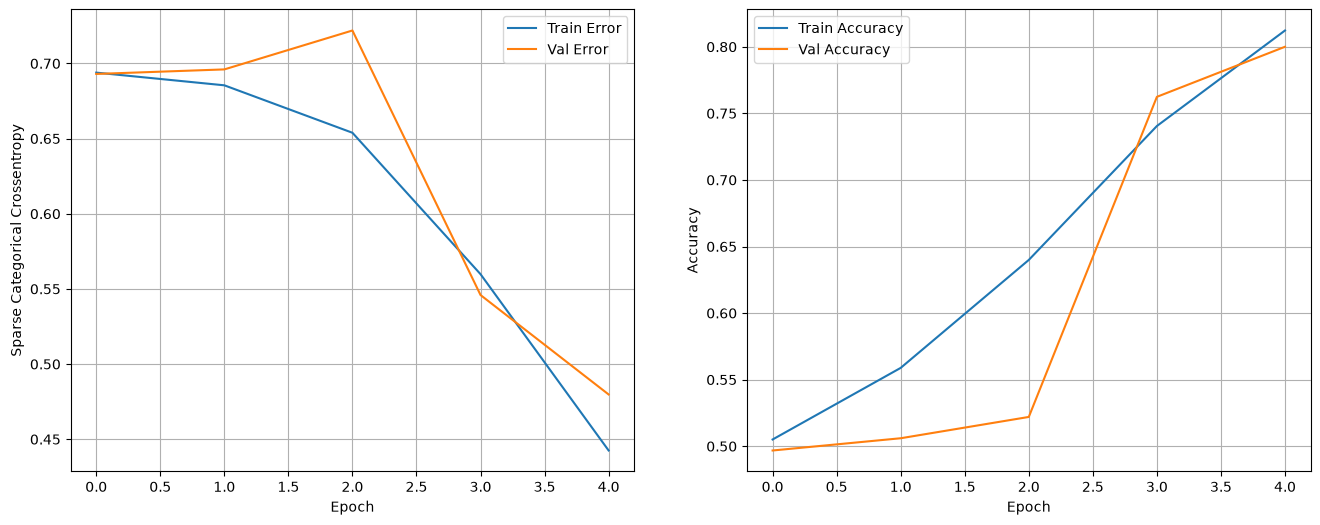

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7842 - loss: 0.4932
Test Loss: 0.49316510558128357
Test Accuracy: 0.7842400074005127


In [17]:
show_loss_accuracy_evolution(history)
results = model.evaluate(x_test_seq, test_labels, verbose=1)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))

In [ ]:
def show_errors(x_test, model, labels, int2word, n_samples=10):
    preds = 1.0 * (model.predict(x_test).flatten() > 0.5)
    bad_pred_inds = np.where(preds != labels)[0]
    n_samples = min(len(bad_pred_inds), n_samples)
    samples_inds = np.random.choice(bad_pred_inds, n_samples)
    for ind in samples_inds:
        print('Predicted : {0}, real : {1}, lenght: {2}'.format(
            int(preds[ind]), labels[ind], len(test_data[ind])))
        print(get_words(test_data[ind], int2word))
        print()
    return

show_errors(x_test_seq, model, test_labels, int2word, n_samples=10)
# vemos alguno de los errores de la spredicciones

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
Predicted : 0, real : 1, lenght: 339
<START> i know little or nothing about <UNK> but <UNK> i was at first a little <UNK> about the plot of this movie it follows three children that were all born during a <UNK> <UNK> and so have no emotion and thus naturally become <UNK> serial <UNK> the plot does sound ridiculous at first but once you <UNK> that a <UNK> <UNK> <UNK> out <UNK> and as you know <UNK> is the emotion planet it all falls into place makes complete sense and it's then that you know you aren't simply watching another silly 80's slasher with a <UNK> brain plot thank god for that seriously though bloody <UNK> is based on a ridiculous premise but it more than makes up for that with it's <UNK> having a bunch of kids going <UNK> <UNK> people may not be the most <UNK> <UNK> ever seen in cinema but when given the choice between this and another dull <UNK> the <UNK> <UNK> i know what i'd <UNK> br br also <UNK> the film out of the <UNK> that some

In [ ]:
reviews = ['the film was really bad and i am very disappointed',
           'The film was very funny entertaining and good we had a great time . brilliant film',
           'this film was just brilliant',
           'the film is not good',
           'the film is not bad',
          'the movie is not bad I like it'] # segun vemos en estas ultimas 3 se esta equivocando el modelo.
#lo que ocurre es que no nos estamos fijando en la posicion de las palabras en el texto si noq  nos centramos mas en que palarbras contiene para poder realizar la prediccion entonces se equivoca ya que ve palrabras buenas cuando deberia ser una reseña negativa y viceversa.
sequences = [vectorize_text_sentence(review.lower(), word2int)
             for review in reviews]

## Padding the sequences
x_pred  = sequence.pad_sequences(sequences, maxlen=max_len, truncating='post', padding='post')# ...

np.round(model.predict(x_pred), 4)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step


array([[0.2895],
       [0.8573],
       [0.8615],
       [0.8635],
       [0.4994],
       [0.44  ]], dtype=float32)

In [20]:
1.0*(model.predict(x_pred) > 0.5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


array([[0.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.]])